# Comparison of different software

In [ ]:
"""
File Name: compare_lat_lon.ipynb

Author:
    Alessio Morea
    B-Open Solutions srl

Date: August 2025

Description:
------------
The primary function of this notebook is to perform a comparative analysis between two NRB datasets
of the same geographic area that were captured from different satellite viewing geometries (e.g., ascending and descending orbits).
It calculates the Root Mean Square Deviation (RMSD) of the Gamma Naught backscatter values.
The RMSD is calculated using three different software packages:
    - S1-RP
    - Opera ISCE3
    - Small C-code
Usage:
------
To use this script, you must provide the file paths for the two NRB products of each software you wish to compare.

"""

In [1]:
import warnings
import numpy as np
import rosel.io
import xarray as xr
import matplotlib.pyplot as plt
import scipy.ndimage

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 20})
plt.rcParams["lines.markersize"] = 12
plt.rcParams["font.family"] = "serif"
cmap = plt.get_cmap("tab10")
colors = [cmap(i) for i in range(cmap.N)]
markers = ["s", "^", "v", "s", "P", "*", "X", "d"]
ls = ["--", "-", "dotted", "-."]

In [2]:
def rmsd_db(x, y):
    r = (10 * (np.log10(x) - np.log10(y))).values
    r = r[np.where(np.isfinite(r))]
    mean = np.mean(r)
    std = np.std(r)
    rm = np.sqrt(np.sum(r**2) / r.size)
    return (mean, std, rm)

def compute_rmsd_spacing(s1, s2, coarsen_steps, n1=None, n2=None):
    print("*"*50)
    print("align datasets")
    (sel_1,n_sel_1),(sel_2,n_sel_2) = align(s1,s2,n1,n2)
    print("*"*50)
    print("remove nan")
    mask = (np.isfinite(sel_1) * (sel_1 > 1e-5)) * (
        np.isfinite(sel_2) * (sel_2 > 1e-5)
    ).values
    mask = xr.DataArray(
        scipy.ndimage.binary_erosion(
            mask, scipy.ndimage.generate_binary_structure(2, 2), iterations=2
        ),
        dims=["y", "x"],
        coords={"x": sel_1.x.values, "y": sel_1.y.values},
    )
    print("*" * 50)
    sel_1 = sel_1.where(mask, np.nan).persist()
    sel_2 = sel_2.where(mask, np.nan).persist()
    if (n1 is not None) and (n2 is not None):
        n_sel_1 = n_sel_1.where(mask, np.nan).persist()
        n_sel_2 = n_sel_2.where(mask, np.nan).persist()
    db_rmsd = []
    for i in coarsen_steps:
        print("_" * 50)
        print(i)
        if (n1 is not None) and (n2 is not None):
            c1 = (
                (sel_1 * n_sel_1).coarsen(x=i, y=i, boundary="trim").sum()
                / ((n_sel_1).coarsen(x=i, y=i, boundary="trim").sum())
            ).compute()
            c2 = (
                (sel_2 * n_sel_2).coarsen(x=i, y=i, boundary="trim").sum()
                / ((n_sel_2).coarsen(x=i, y=i, boundary="trim").sum())
            ).compute()
        else:
            c1 = (sel_1).coarsen(x=i, y=i, boundary="trim").sum().compute()
            c2 = sel_2.coarsen(x=i, y=i, boundary="trim").sum().compute()
        mean, std, rm = rmsd_db(c1, c2)
        print(f"DB: {mean} +- {std}")
        db_rmsd.append(rm)
    return db_rmsd


def align(s1, s2, n1=None, n2=None):
    print("="*50)
    res = s1.rio.resolution()
    if res[0] > 0:
        x1 = np.maximum(s1.x[0], s2.x[0]).values
        x2 = np.minimum(s1.x[-1], s2.x[-1]).values
    else:
        x1 = np.minimum(s1.x[0], s2.x[0]).values
        x2 = np.maximum(s1.x[-1], s2.x[-1]).values
    if res[1] < 0:
        y1 = np.minimum(s1.y[0], s2.y[0]).values
        y2 = np.maximum(s1.y[-1], s2.y[-1]).values
    else:
        y1 = np.maximum(s1.y[0], s2.y[0]).values
        y2 = np.minimum(s1.y[-1], s2.y[-1]).values
    sel_1 = s1.sel(
        x=slice(x1 - res[0] / 2, x2 + res[0] / 2),
        y=slice(y1 - res[1] / 2, y2 + res[1] / 2),
    ).chunk(1024)
    sel_2 = s2.sel(
        x=slice(x1 - res[0] / 2, x2 + res[0] / 2),
        y=slice(y1 - res[1] / 2, y2 + res[1] / 2),
    ).chunk(1024)
    if (n1 is not None):
        n_sel_1 = n1.sel(
            x=slice(x1 - res[0] / 2, x2 + res[0] / 2),
            y=slice(y1 - res[1] / 2, y2 + res[1] / 2),
        ).chunk(1024)
    else:
        n_sel_1=None
    if (n2 is not None):
        n_sel_2 = n2.sel(
            x=slice(x1 - res[0] / 2, x2 + res[0] / 2),
            y=slice(y1 - res[1] / 2, y2 + res[1] / 2),
        ).chunk(1024)
    else:
        n_sel_2=None
    print("resolution:", res)
    print("x_size", sel_1.x.size, sel_2.x.size)
    print("y_size", sel_1.y.size, sel_2.y.size)
    print("x1:", sel_1.x.values)
    print("x2:", sel_2.x.values)
    print("y1:", sel_1.y.values)
    print("y2:", sel_2.y.values)
    sel_2["x"] = sel_1.x.values
    sel_2["y"] = sel_1.y.values
    if (n2 is not None): 
        n_sel_2["x"] = sel_1.x.values
        n_sel_2["y"] = sel_1.y.values
    return (sel_1, n_sel_1), (sel_2, n_sel_2)

## READ AND ALIGN ALL DATASETS

In [ ]:
data_44_path = "/home/morea/SENTINEL1/SALZBURG/44/SW_COMPARISON/ESA/WDIR_DYNAMIC/nrb"
data_95_path = "/home/morea/SENTINEL1/SALZBURG/95/SW_COMPARISON/ESA/WDIR_DYNAMIC/nrb"

In [ ]:
data_44 = rosel.io.read(
    data_44_path,
    consolidate_metadata=False,
    mask_and_scale=False,
).sel(y=slice(None, None, -1))
mask_44 = (data_44.mask == 0).compute()
nrb_44 = data_44.gamma0.squeeze().where(mask_44, np.nan)
nl_44 = data_44.nlooks.where(mask_44, np.nan)

In [ ]:
data_95 = rosel.io.read(
    data_95_path,
    consolidate_metadata=False,
    mask_and_scale=False,
).sel(y=slice(None, None, -1))
mask_95 = (data_95.mask == 0).compute()
nrb_95 = data_95.gamma0.squeeze().where(mask_95, np.nan)
nl_95 = data_95.nlooks.where(mask_95, np.nan)

In [ ]:
opera_95_path = "/home/morea/SENTINEL1/SALZBURG/95/SW_COMPARISON/OPERA/output.bck/OPERA_L2_RTC-S1_20241019T051900Z_20250828T091700Z_S1A_0_v1.0.2"
opera_44_path = "/home/morea/SENTINEL1/SALZBURG/44/SW_COMPARISON/OPERA/output/OPERA_L2_RTC-S1_20241015T165930Z_20250827T153330Z_S1A_0_v1.0.2"

In [ ]:
opera_95_mask = (
    (xr.open_dataset(f"{opera_95_path}_mask.tif").band_data.squeeze().drop_vars("band"))
    == 0
).compute()
opera_95_vh = (
    (xr.open_dataset(f"{opera_95_path}_VH.tif").band_data.squeeze().drop_vars("band"))
    .chunk(1024)
    .where(opera_95_mask, np.nan)
)
opera_95_vv = (
    (xr.open_dataset(f"{opera_95_path}_VV.tif").band_data.squeeze().drop_vars("band"))
    .chunk(1024)
    .persist()
).where(opera_95_mask, np.nan)
opera_95_nlook = rosel.io.read(f"{opera_95_path}_number_of_looks.tif").where(
    opera_95_mask, np.nan
)

In [ ]:
opera_44_mask = (
    (xr.open_dataset(f"{opera_44_path}_mask.tif").band_data.squeeze().drop_vars("band"))
    == 0
).compute()
opera_44_vh = (
    (xr.open_dataset(f"{opera_44_path}_VH.tif").band_data.squeeze().drop_vars("band"))
    .chunk(1024)
    .persist()
).where(opera_44_mask, np.nan)
opera_44_vv = (
    (xr.open_dataset(f"{opera_44_path}_VV.tif").band_data.squeeze().drop_vars("band"))
    .chunk(1024)
    .persist()
).where(opera_44_mask, np.nan)
opera_44_nlook = (
    (
        xr.open_dataset(f"{opera_44_path}_number_of_looks.tif")
        .band_data.squeeze()
        .drop_vars("band")
    ).chunk(1024)
).where(opera_44_mask, np.nan)

In [ ]:
opera_44 = xr.concat(
    [
        opera_44_vh.assign_coords({"polarization": "V:H"}).expand_dims(
            {"polarization": 1}
        ),
        opera_44_vv.assign_coords({"polarization": "V:V"}).expand_dims(
            {"polarization": 1}
        ),
    ],
    dim="polarization",
)
opera_95 = xr.concat(
    [
        opera_95_vh.assign_coords({"polarization": "V:H"}).expand_dims(
            {"polarization": 1}
        ),
        opera_95_vv.assign_coords({"polarization": "V:V"}).expand_dims(
            {"polarization": 1}
        ),
    ],
    dim="polarization",
)

In [ ]:
# The output from Small software was converted into an Xarray DataArray
# The coordinates for the DataArray where obtained by the relative .hdr file
# x = [LonEasting + i * PixelSpacingLonEast for i in range(NrOfPixelsPerLine)]
# y = [LatNorthing - i * PixelSpacingLatNorth for i in range(NrOfLinesPerImage)]

In [ ]:
small_path_44 = "/home/morea/SENTINEL1/SALZBURG/44/SW_COMPARISON/SMALL"
small_path_95 = "/home/morea/SENTINEL1/SALZBURG/95/SW_COMPARISON/SMALL"

In [ ]:
small_44 = xr.concat(
    [
        rosel.io.read(f"{small_path_44}/nrb_vh").__xarray_dataarray_variable__,
        rosel.io.read(f"{small_path_44}/nrb_vv").__xarray_dataarray_variable__,
    ],
    dim="polarization",
)
x = small_44.x.values - small_44.rio.resolution()[0] / 2
y = small_44.y.values - small_44.rio.resolution()[1] / 2
small_44["x"] = x
small_44["y"] = y

In [ ]:
small_95 = xr.concat(
    [
        rosel.io.read(f"{small_path_95}/nrb_vh").__xarray_dataarray_variable__,
        rosel.io.read(f"{small_path_95}/nrb_vv").__xarray_dataarray_variable__,
    ],
    dim="polarization",
)
x = small_95.x.values - small_95.rio.resolution()[0] / 2
y = small_95.y.values - small_95.rio.resolution()[1] / 2
small_95["x"] = x
small_95["y"] = y

In [ ]:
# The x or y dimension must be increasing (or decreasing) for all datasets.
# A dataset can be inverted with: 
# a = a.sel(y=slice(None,None,-1))

In [ ]:

(nrb_44_ali, nl_44_ali), (opera_44_ali, opera_nl_44_ali) = align(
    s1=nrb_44, s2=opera_44, n1=nl_44, n2=opera_44_nlook
)
(nrb_95_ali, nl_95_ali), (opera_95_ali, opera_nl_95_ali) = align(
    s1=nrb_95, s2=opera_95, n1=nl_95, n2=opera_95_nlook
)
(nrb_44_ali, nl_44_ali), (small_44_ali, _) = align(
    s1=nrb_44_ali, s2=small_44, n1=nl_44_ali, n2=None
)
(nrb_95_ali, nl_95_ali), (small_95_ali, _) = align(
    s1=nrb_95_ali, s2=small_95, n1=nl_95_ali, n2=None)
(nrb_44_ali, nl_44_ali), (opera_44_ali, opera_nl_44_ali) = align(
    s1=nrb_44_ali, s2=opera_44_ali, n1=nl_44_ali, n2=opera_nl_44_ali
)
(nrb_95_ali, nl_95_ali), (opera_95_ali, opera_nl_95_ali) = align(
    s1=nrb_95_ali, s2=opera_95_ali, n1=nl_95_ali, n2=opera_nl_95_ali
)

In [ ]:
# SAVE ALIGNED DATA TO FILE
save_path = "/home/morea/SW_COMPARISON"

In [ ]:
rosel.io.write(opera_95_ali, f"{save_path}/opera_95")
rosel.io.write(opera_nl_95_ali, f"{save_path}/opera_nl_95")
rosel.io.write(opera_44_ali, f"{save_path}/opera_44")
rosel.io.write(opera_nl_44_ali, f"{save_path}/opera_nl_44")
rosel.io.write(small_44_ali, f"{save_path}/small_44")
rosel.io.write(small_95_ali, f"{save_path}/small_95")
rosel.io.write(nrb_95_ali, f"{save_path}/nrb_95")
rosel.io.write(nl_95_ali, f"{save_path}/nl_95")
rosel.io.write(nrb_44_ali, f"{save_path}/nrb_44")
rosel.io.write(nl_44_ali, f"{save_path}/nl_44")

In [3]:
save_path = "/home/morea/SW_COMPARISON"

In [4]:
# CHECKPOINT: restart from here in case of failure
nrb_44_ali = rosel.io.read(f"{save_path}/nrb_44", consolidate_metadata=False)
nl_44_ali = rosel.io.read(f"{save_path}/nl_44", consolidate_metadata=False)
nrb_95_ali = rosel.io.read(f"{save_path}/nrb_95", consolidate_metadata=False)
nl_95_ali = rosel.io.read(f"{save_path}/nl_95", consolidate_metadata=False)
opera_44_ali = rosel.io.read(f"{save_path}/opera_44", consolidate_metadata=False)
opera_nl_44_ali = rosel.io.read(
   f"{save_path}/opera_nl_44", consolidate_metadata=False
)
opera_95_ali = rosel.io.read(f"{save_path}/opera_95", consolidate_metadata=False)
opera_nl_95_ali = rosel.io.read(
    f"{save_path}/opera_nl_95", consolidate_metadata=False
)
small_44_ali = rosel.io.read(f"{save_path}/small_44", consolidate_metadata=False)
small_95_ali = rosel.io.read(f"{save_path}/small_95", consolidate_metadata=False)

In [ ]:
# This part of the script requires a significant amount of RAM.
# If it fails, consider selecting a smaller subset of the data.
# --------------------------------------------------------------
# yslice = slice(47.5,46)
# xslice = slice(11,13)
# nrb_44_ali = nrb_44_ali.sel(x = xslice, y = yslice)
# nl_44_ali = nl_44_ali.sel(x = xslice, y = yslice)
# nrb_95_ali = nrb_95_ali.sel(x = xslice, y = yslice)
# nl_95_ali = nl_95_ali.sel(x = xslice, y = yslice)
# opera_44_ali = opera_44_ali.sel(x = xslice, y = yslice)
# opera_nl_44_ali = opera_nl_44_ali.sel(x = xslice, y = yslice)
# opera_95_ali = opera_95_ali.sel(x = xslice, y = yslice)
# opera_nl_95_ali = opera_nl_95_ali.sel(x = xslice, y = yslice)
# small_44_ali = small_44_ali.sel(x = xslice, y = yslice)
# small_95_ali = small_95_ali.sel(x = xslice, y = yslice)

In [7]:
nrbs = {
    "SMALL": [small_44_ali, small_95_ali],
    "S1-ARD": [nrb_44_ali, nrb_95_ali],
    "OPERA": [opera_44_ali, opera_95_ali],
}
nlooks = {
    "S1-ARD": [nl_44_ali, nl_95_ali],
    "OPERA": [opera_nl_44_ali, opera_nl_95_ali],
}

In [8]:
coarsen_steps = [1, 2, 4, 6, 8, 10, 15, 20, 30, 40, 50]

In [9]:
result_db = {"V:H": {}, "V:V": {}}
for k, v in nrbs.items():
    for pol in ["V:H", "V:V"]:
        print("=" * 70)
        print(k, pol)
        s1 = v[0].sel(polarization=pol).squeeze()
        s2 = v[1].sel(polarization=pol).squeeze()
        n1 = None if k == "SMALL" else nlooks[k][0]
        n2 = None if k == "SMALL" else nlooks[k][1]
        r_db = compute_rmsd_spacing(s1, s2, coarsen_steps, n1, n2)
        result_db[pol][k] = r_db

SMALL V:H
**************************************************
align datasets
resolution: (8.333333333333333e-05, -8.333333333333241e-05)
x_size 42568 42568
y_size 16579 16579
x1: [11.15070833 11.15079167 11.150875   ... 14.69779167 14.697875
 14.69795833]
x2: [11.15070833 11.15079167 11.150875   ... 14.69779167 14.697875
 14.69795833]
y1: [48.07754167 48.07745833 48.077375   ... 46.69620833 46.696125
 46.69604167]
y2: [48.07754167 48.07745833 48.077375   ... 46.69620833 46.696125
 46.69604167]
**************************************************
remove nan
**************************************************
__________________________________________________
1
DB: 0.1272492466863934 +- 4.056959393576229
__________________________________________________
2
DB: 0.1138976299342036 +- 3.7615567155953586
__________________________________________________
4
DB: 0.09248139697148507 +- 3.354017453661049
__________________________________________________
6
DB: 0.07789288160924393 +- 3.10742945510596

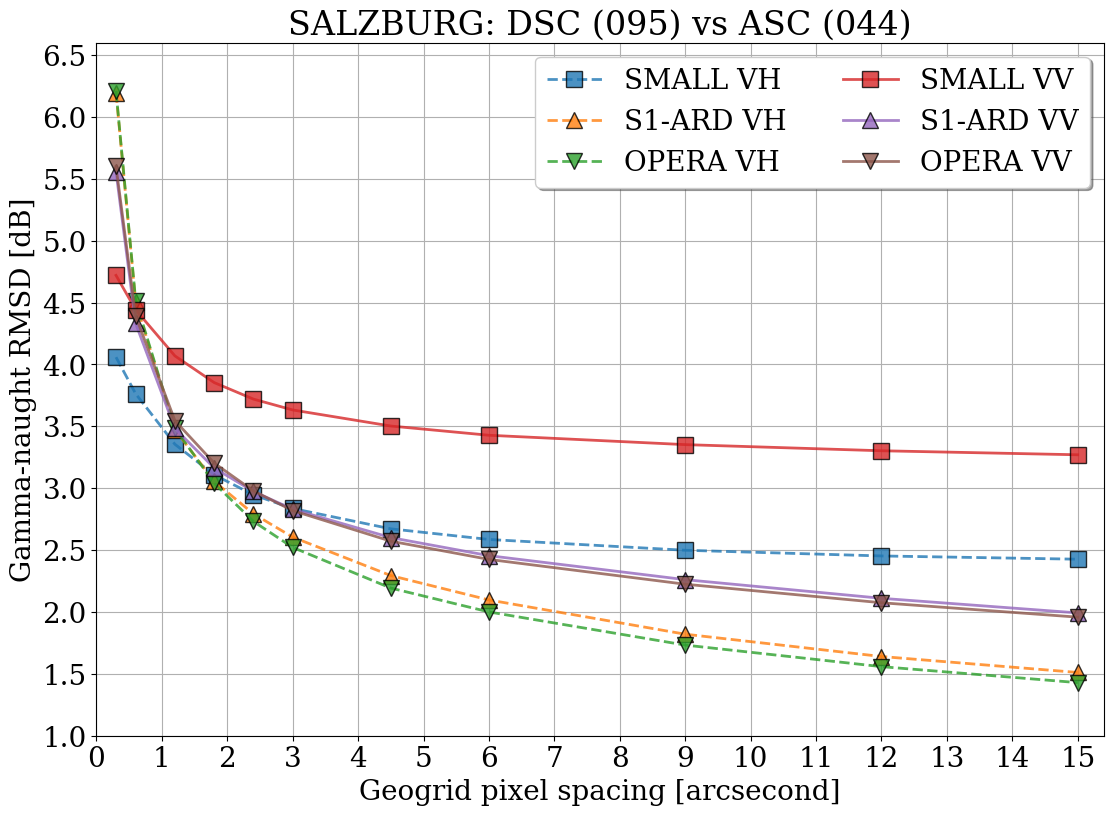

In [10]:
fig = plt.figure(figsize=(13, 9))
plt.title("SALZBURG: DSC (095) vs ASC (044)")
for h, pol in enumerate(["V:H", "V:V"]):
    for z, (s, v) in enumerate(result_db[pol].items()):
        plt.plot(
            np.array(coarsen_steps) * 0.3,
            v,
            marker=markers[z % len(markers)],
            ls=ls[h],
            color=colors[(z + h * 3) % len(markers)],
            alpha=0.8,
            label=f"{s} {''.join([pol[0],pol[2]])}",
            lw=2,
            mec="black",
        )

plt.xlabel("Geogrid pixel spacing [arcsecond]")
plt.ylabel("Gamma-naught RMSD [dB]")
plt.ylim(1, 6.6)
plt.xlim(0, 15.4)
xticks = np.arange(0, 16, 1)
yticks = np.arange(1, 7.0, 0.5)
plt.xticks(xticks, labels=[f"{i:.0f}" for i in xticks])
plt.yticks(yticks, labels=[f"{i:.1f}" for i in yticks])
plt.grid()
plt.legend(loc="upper right", ncol=2, shadow=True)